# Load the milling tool-wear dataset into pandas

This notebook loads `mill.mat` and creates a DataFrame with **one row per machining record**. Each sensor signal remains a NumPy array in its cell. Place `mill.mat` in the same directory as this notebook.

**Requirements:** `numpy`, `pandas`, `scipy`, and `matplotlib` (optional for the final plot).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.io import loadmat

file_path = Path("mill.mat")
if not file_path.exists():
    raise FileNotFoundError(f"Could not find {file_path.resolve()}. Put mill.mat beside this notebook.")

## 1. Read the MATLAB structure
The `mill` variable contains MATLAB struct records. `squeeze_me=True` simplifies their shapes and `struct_as_record=False` enables field access.

In [2]:
mat = loadmat(file_path, squeeze_me=True, struct_as_record=False)
runs = np.atleast_1d(mat["mill"]).ravel()
print(f"Loaded {len(runs)} machining records")
print("Fields:", runs[0]._fieldnames)

Loaded 167 machining records
Fields: ['case', 'run', 'VB', 'time', 'DOC', 'feed', 'material', 'smcAC', 'smcDC', 'vib_table', 'vib_spindle', 'AE_table', 'AE_spindle']


## 2. Convert the records into a DataFrame
Scalar fields become numeric columns. The six time-series signal fields are preserved as arrays rather than expanded into thousands of columns.

In [3]:
records = [
    {field: getattr(run, field) for field in run._fieldnames}
    for run in runs
]
df = pd.DataFrame(records)

scalar_cols = ["case", "run", "VB", "time", "DOC", "feed", "material"]
signal_cols = ["smcAC", "smcDC", "vib_table", "vib_spindle", "AE_table", "AE_spindle"]
for column in scalar_cols:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("DataFrame shape:", df.shape)
display(df[scalar_cols].head())

DataFrame shape: (167, 13)


,case,run,VB,time,DOC,feed,material
0,1,1,0.00,2,1.5,0.5,1
1,1,2,NaN,4,1.5,0.5,1
2,1,3,NaN,6,1.5,0.5,1
3,1,4,0.11,7,1.5,0.5,1
4,1,5,NaN,11,1.5,0.5,1


## 3. Check missing values and sensor lengths

In [4]:
print("Missing scalar values:")
display(df[scalar_cols].isna().sum().to_frame("missing_count"))
print("Signal lengths in the first record:")
print({name: len(df.at[0, name]) for name in signal_cols})

Missing scalar values:


,missing_count
case,0
run,0
VB,21
time,0
DOC,0
feed,0
material,0


Signal lengths in the first record:
{'smcAC': 9000, 'smcDC': 9000, 'vib_table': 9000, 'vib_spindle': 9000, 'AE_table': 9000, 'AE_spindle': 9000}


## 4. Example: access and plot a signal

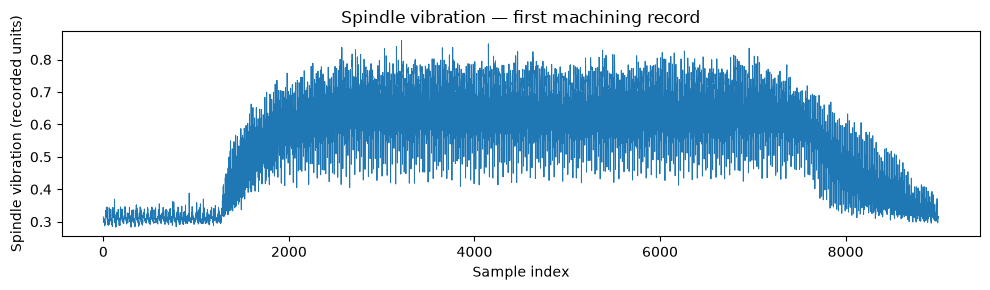

In [5]:
import matplotlib.pyplot as plt

signal = np.asarray(df.at[0, "vib_spindle"]).ravel()
plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(signal)), signal, linewidth=0.7)
plt.xlabel("Sample index")
plt.ylabel("Spindle vibration (recorded units)")
plt.title("Spindle vibration — first machining record")
plt.tight_layout()
plt.show()